In [1]:

import pandas as pd

df = pd.read_csv('/content/spam.csv', encoding='latin-1')

df.head()


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [2]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()


Dataset shape: (5572, 5)

Column names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (5572, 5)


In [4]:
print("\nColumn names:")
print(df.columns)


Column names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')


In [5]:
print("\nDataset information:")
df.info()



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [6]:
df.head(10)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN
5,spam,FreeMsg Hey there darling it's been 3 week's n...,NaN,NaN,NaN
6,ham,Even my brother is not like to speak with me. ...,NaN,NaN,NaN
7,ham,As per your request 'Melle Melle (Oru Minnamin...,NaN,NaN,NaN
8,spam,WINNER!! As a valued network customer you have...,NaN,NaN,NaN
9,spam,Had your mobile 11 months or more? U R entitle...,NaN,NaN,NaN


In [7]:
df = df[['v1', 'v2']]

In [8]:
df.columns = ['label', 'message']

In [9]:
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [10]:
print(df['label'].value_counts())

label
ham     4825
spam     747
Name: count, dtype: int64


In [11]:
print("Missing values:")
print(df.isnull().sum())


print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values:
label      0
message    0
dtype: int64

Number of duplicate rows:
403


In [12]:


df = df.drop_duplicates()

df = df.reset_index(drop=True)
print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (5169, 2)


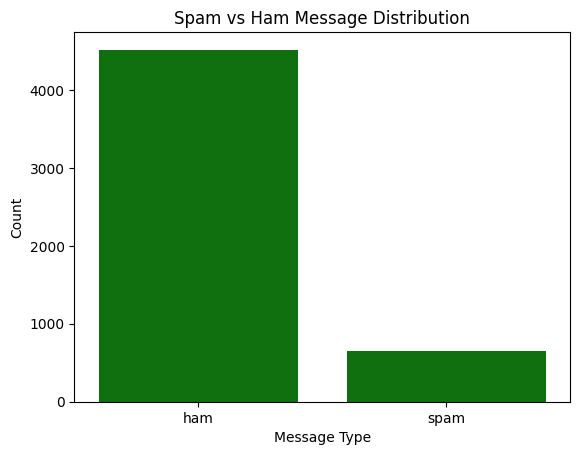

In [14]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='label',color='green')
plt.title('Spam vs Ham Message Distribution')
plt.xlabel('Message Type')
plt.ylabel('Count')
plt.show()


In [15]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())


Missing values:
label      0
message    0
dtype: int64

Duplicate rows:
0


In [16]:

df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Dataset shape after cleaning:", df.shape)


Dataset shape after cleaning: (5169, 2)


In [17]:

import re
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text
df['clean_message'] = df['message'].apply(clean_text)
df[['message', 'clean_message']].head()


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [18]:

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=3000)

X = tfidf.fit_transform(df['clean_message'])
print("TF-IDF matrix shape:", X.shape)


TF-IDF matrix shape: (5169, 3000)


In [19]:

y = df['label'].map({'ham': 0, 'spam': 1})

print(y.head())
print("\nTarget shape:", y.shape)


0    0
1    0
2    1
3    0
4    0
Name: label, dtype: int64

Target shape: (5169,)


In [20]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (4135, 3000)
Testing data: (1034, 3000)


In [22]:

from sklearn.naive_bayes import MultinomialNB
model = MultinomialNB()
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [23]:

from sklearn.metrics import accuracy_score, classification_report
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam']
))


Accuracy: 0.9709864603481625
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       903
        Spam       0.99      0.78      0.87       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034



In [24]:

def predict_spam(message):
    cleaned = clean_text(message)
    message_vector = tfidf.transform([cleaned])
    prediction = model.predict(message_vector)[0]

    if prediction == 1:
        print("Prediction: SPAM 🚨")
    else:
        print("Prediction: HAM ✅")

# Test 1
predict_spam("Congratulations! You have won a free prize. Call now!")

# Test 2
predict_spam("Hey, are we meeting today?")


Prediction: SPAM 🚨
Prediction: HAM ✅


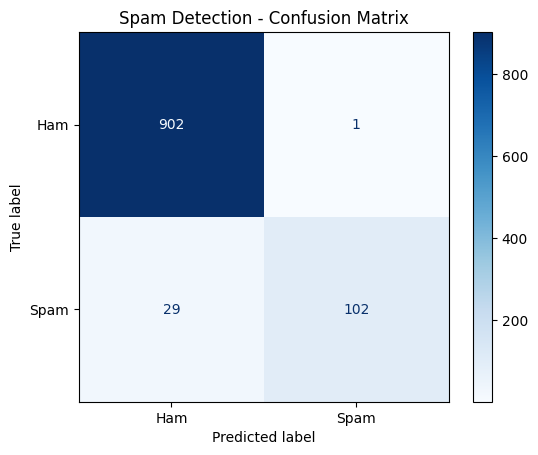

In [25]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['Ham', 'Spam'],
    cmap='Blues'
)

plt.title('Spam Detection - Confusion Matrix')
plt.show()
